# Human Activity Recognition — Clustering Analysis

Unsupervised clustering of smartphone accelerometer/gyroscope sensor data to uncover hidden human-activity groupings without labels.

## 1. Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

df = pd.read_csv("human_activity_master.csv")
print(df.shape)
df.head()

(7352, 561)


,tBodyAcc_mean_X,tBodyAcc_mean_Y,tBodyAcc_mean_Z,tBodyAcc_std_X,tBodyAcc_std_Y,tBodyAcc_std_Z,tBodyAcc_mad_X,tBodyAcc_mad_Y,tBodyAcc_mad_Z,tBodyAcc_max_X,...,fBodyBodyGyroJerkMag_meanFreq,fBodyBodyGyroJerkMag_skewness,fBodyBodyGyroJerkMag_kurtosis,"angletBodyAccMean,gravity","angletBodyAccJerkMean,gravityMean","angletBodyGyroMean,gravityMean","angletBodyGyroJerkMean,gravityMean","angleX,gravityMean","angleY,gravityMean","angleZ,gravityMean"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


## 2. Exploratory Data Analysis

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 561 entries, tBodyAcc_mean_X to angleZ,gravityMean
dtypes: float64(561)
memory usage: 31.5 MB


In [3]:
df.isnull().sum()

,0
tBodyAcc_mean_X,0
tBodyAcc_mean_Y,0
tBodyAcc_mean_Z,0
tBodyAcc_std_X,0
tBodyAcc_std_Y,0
...,...
"angletBodyGyroMean,gravityMean",0
"angletBodyGyroJerkMean,gravityMean",0
"angleX,gravityMean",0
"angleY,gravityMean",0


In [4]:
df.columns

Index(['tBodyAcc_mean_X', 'tBodyAcc_mean_Y', 'tBodyAcc_mean_Z',
       'tBodyAcc_std_X', 'tBodyAcc_std_Y', 'tBodyAcc_std_Z', 'tBodyAcc_mad_X',
       'tBodyAcc_mad_Y', 'tBodyAcc_mad_Z', 'tBodyAcc_max_X',
       ...
       'fBodyBodyGyroJerkMag_meanFreq', 'fBodyBodyGyroJerkMag_skewness',
       'fBodyBodyGyroJerkMag_kurtosis', 'angletBodyAccMean,gravity',
       'angletBodyAccJerkMean,gravityMean', 'angletBodyGyroMean,gravityMean',
       'angletBodyGyroJerkMean,gravityMean', 'angleX,gravityMean',
       'angleY,gravityMean', 'angleZ,gravityMean'],
      dtype='object', length=561)

## 3. Preprocessing

In [5]:
X = df.copy()
X = X.loc[:, X.nunique() > 1]
X = X.fillna(X.mean())
print(X.shape)

(7352, 561)


In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

### Remove highly correlated features

In [7]:
corr = X_scaled.corr().abs()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]

X_clean = X_scaled.drop(columns=to_drop)

print("Dropped:", len(to_drop))
print("Remaining features:", X_clean.shape[1])

Dropped: 308
Remaining features: 253


The dataset contains 561 sensor-derived features from smartphone accelerometer and gyroscope signals. Because many features are highly redundant, we removed features with correlation higher than 0.95. This reduces multicollinearity and improves clustering performance by preventing biased distance calculations. After standardization, all features were scaled to have zero mean and unit variance, ensuring that no feature dominates due to scale differences.

## 4. Choosing the Number of Clusters

### Elbow Method

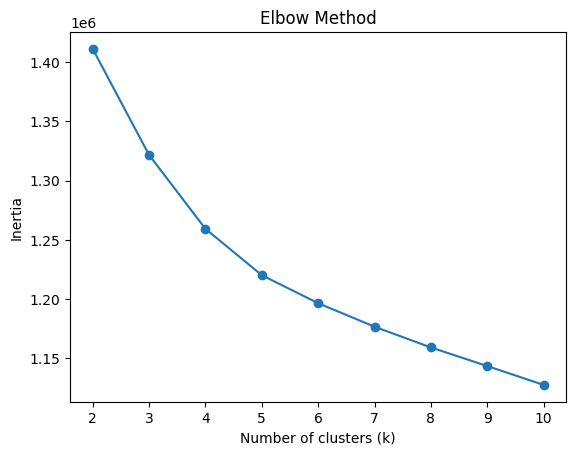

In [8]:
inertia = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_clean)
    inertia.append(kmeans.inertia_)

plt.plot(K_range, inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.show()

### Silhouette Analysis

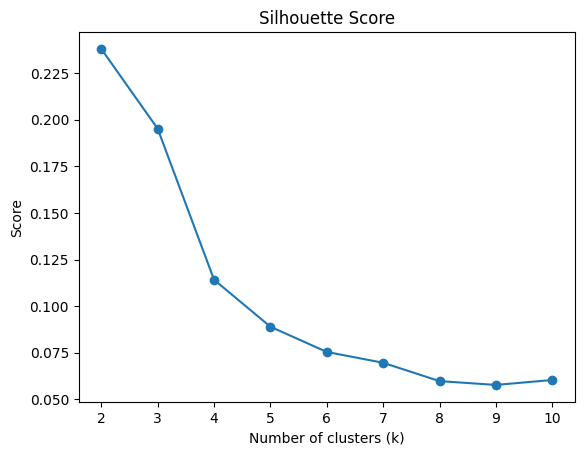

In [9]:
sil_scores = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_clean)
    sil_scores.append(silhouette_score(X_clean, labels))

plt.plot(K_range, sil_scores, marker='o')
plt.title("Silhouette Score")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Score")
plt.show()

The elbow curve does not show a sharp inflection point; inertia decreases smoothly and gradually across the tested range of k, without a clear "elbow." The silhouette score gives a more decisive signal: it is highest at k = 2 (approximately 0.22-0.24) and drops sharply by k = 4, continuing to decline through k = 10. Since k = 2 collapses the data into only two broad groups, k = 3 was selected instead — it retains a comparatively strong silhouette score (approximately 0.18-0.20) while allowing for a slightly more informative split than a binary grouping.

## 5. KMeans Clustering

In [10]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_clean)

In [11]:
df_clusters = X_clean.copy()
df_clusters["Cluster"] = clusters

df_clusters.head()

,tBodyAcc_mean_X,tBodyAcc_mean_Y,tBodyAcc_mean_Z,tBodyAcc_std_X,tBodyAcc_std_Y,tBodyAcc_std_Z,tBodyAcc_max_Z,tBodyAcc_min_Z,tBodyAcc_energy_Y,tBodyAcc_energy_Z,...,fBodyBodyGyroMag_skewness,fBodyBodyGyroJerkMag_min,fBodyBodyGyroJerkMag_maxInds,fBodyBodyGyroJerkMag_meanFreq,fBodyBodyGyroJerkMag_skewness,"angletBodyAccMean,gravity","angletBodyAccJerkMean,gravityMean","angletBodyGyroMean,gravityMean","angletBodyGyroJerkMean,gravityMean",Cluster
0,0.200642,-0.063683,-0.419628,-0.868814,-0.939441,-0.737529,-0.637379,0.738383,-0.775696,-0.670496,...,2.571343,-0.616153,-0.706661,-0.795359,0.025960,-0.360603,0.062940,-0.778427,-0.026080,0
1,0.055948,0.031486,-0.253908,-0.875426,-0.923902,-0.849304,-0.889197,0.766503,-0.775105,-0.687585,...,-0.253097,-0.633698,-0.706661,0.130614,-0.897357,0.133011,-0.021461,-1.218805,1.484470,0
2,0.073515,-0.043416,-0.076295,-0.869039,-0.907760,-0.893785,-0.889197,0.822606,-0.774088,-0.692379,...,-0.862529,-0.641077,2.398628,1.152336,-0.260878,-0.377840,0.391976,0.151207,1.704201,0
3,0.066696,-0.208422,-0.249712,-0.870626,-0.940022,-0.921805,-0.927662,0.817653,-0.774691,-0.692533,...,0.072130,-0.640381,-0.263048,1.112769,0.591045,-0.135025,-0.033637,1.037851,-1.003019,0
4,0.030469,0.027587,-0.109848,-0.875188,-0.934878,-0.921343,-0.910626,0.817653,-0.775640,-0.693672,...,-0.785768,-0.649103,-0.263048,-0.149577,-0.138515,0.340406,0.268486,1.125918,-1.276282,0


### PCA Visualization

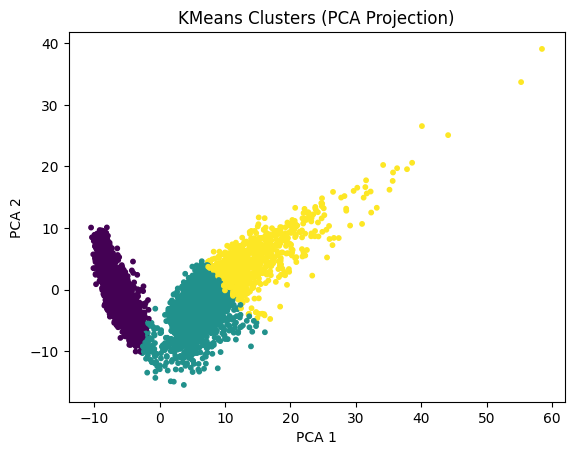

In [12]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_clean)

plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap='viridis', s=10)
plt.title("KMeans Clusters (PCA Projection)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()

### Cluster Centers

In [13]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=X_clean.columns)
centers

,tBodyAcc_mean_X,tBodyAcc_mean_Y,tBodyAcc_mean_Z,tBodyAcc_std_X,tBodyAcc_std_Y,tBodyAcc_std_Z,tBodyAcc_max_Z,tBodyAcc_min_Z,tBodyAcc_energy_Y,tBodyAcc_energy_Z,...,fBodyBodyGyroMag_meanFreq,fBodyBodyGyroMag_skewness,fBodyBodyGyroJerkMag_min,fBodyBodyGyroJerkMag_maxInds,fBodyBodyGyroJerkMag_meanFreq,fBodyBodyGyroJerkMag_skewness,"angletBodyAccMean,gravity","angletBodyAccJerkMean,gravityMean","angletBodyGyroMean,gravityMean","angletBodyGyroJerkMean,gravityMean"
0,0.037340,0.029540,0.000788,-0.835290,-0.872199,-0.831973,-0.809024,0.766485,-0.752935,-0.666421,...,-0.148832,0.200343,-0.599434,-0.087251,0.113839,-0.196819,0.004074,0.012303,0.010112,0.007635
1,-0.106760,-0.034458,0.021403,0.777888,0.866910,0.835151,0.809776,-0.650530,0.647598,0.581082,...,-0.104879,-0.147101,0.338253,0.098926,-0.248703,0.208741,0.045965,-0.026549,-0.069758,0.035798
2,0.100936,-0.034428,-0.051938,1.422540,1.360494,1.278954,1.249018,-1.449997,1.404780,1.225324,...,0.809969,-0.431414,1.523663,0.108204,0.132248,0.277033,-0.120665,0.013542,0.120694,-0.111074


## 6. Anomaly Detection

In [14]:
distances = np.min(kmeans.transform(X_clean), axis=1)

In [15]:
threshold = np.percentile(distances, 95)
anomalies = X_clean[distances >= threshold]

print(anomalies.shape)

(368, 253)


## 7. Comparing Clustering Algorithms

In [16]:
agglo = AgglomerativeClustering(n_clusters=3)
agglo_labels = agglo.fit_predict(X_clean)

agglo_silhouette = silhouette_score(X_clean, agglo_labels)
print("Agglomerative Silhouette:", agglo_silhouette)

Agglomerative Silhouette: 0.22521824923254294


In [17]:
gmm = GaussianMixture(n_components=3, random_state=42)
gmm_labels = gmm.fit_predict(X_clean)

gmm_silhouette = silhouette_score(X_clean, gmm_labels)
print("GMM Silhouette:", gmm_silhouette)

GMM Silhouette: 0.1399533062766243


In [18]:
birch = Birch(n_clusters=3)
birch_labels = birch.fit_predict(X_clean)

birch_silhouette = silhouette_score(X_clean, birch_labels)
print("BIRCH Silhouette:", birch_silhouette)

BIRCH Silhouette: 0.22521824923254294


In [19]:
results = pd.DataFrame({
    "Model": ["KMeans", "Agglomerative", "GMM", "BIRCH"],
    "Silhouette Score": [
        silhouette_score(X_clean, clusters),
        agglo_silhouette,
        gmm_silhouette,
        birch_silhouette
    ]
})

results

,Model,Silhouette Score
0,KMeans,0.195124
1,Agglomerative,0.225218
2,GMM,0.139953
3,BIRCH,0.225218


### Comparison of Clustering Models

The performance of the clustering algorithms was evaluated using the Silhouette Score, which measures how well-separated and compact the clusters are.

## 📌 Final Conclusion

This project demonstrated how unsupervised learning can uncover hidden structures in human motion data without using labels.

Key findings include:

- Feature scaling and correlation removal were essential for meaningful clustering
- KMeans successfully identified general motion categories
- PCA visualization confirmed partial separation of clusters
- Anomaly detection revealed unusual or transitional movements
- GMM provided the best statistical clustering performance due to its probabilistic nature